In [1]:
!pip install -q \
    transformers==4.45.2 \
    datasets==3.0.1 \
    peft==0.13.2 \
    accelerate==1.0.1 \
    evaluate==0.4.3 \
    scikit-learn \
    pandas \
    numpy \
    torchmetrics

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.6.1 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [20]:
import torch
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from peft import LoraConfig, TaskType, get_peft_model
from datasets import load_dataset

from tqdm.auto import tqdm
import matplotlib.pyplot as plt

## Import the dataset

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [35]:
DATASET_PATH = '/content/drive/MyDrive/SkillSwap/Datasets/skillswap_intent_dataset.csv'

In [36]:
dataset = load_dataset("csv", data_files = DATASET_PATH)
dataset

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3000
    })
})

## Train - Test Splitting

In [37]:
dataset['train'] = dataset['train'].class_encode_column('label')
dataset['train']

Stringifying the column:   0%|          | 0/3000 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/3000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 3000
})

In [38]:
dataset = dataset['train'].train_test_split(
    test_size = 0.05,
    seed = 42,
    stratify_by_column = 'label'
)

In [39]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2850
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 150
    })
})

## Tokenization

In [40]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

In [41]:
def tokenize_function(examples):
    return tokenizer(examples['text'], padding = 'max_length', truncation = True)

In [42]:
tokenized_datasets = dataset.map(tokenize_function, batched = True)

Map:   0%|          | 0/2850 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

In [43]:
tokenized_datasets = tokenized_datasets.remove_columns(['text'])
tokenized_datasets = tokenized_datasets.rename_column('label', 'labels')
tokenized_datasets.set_format('torch')

## Dataloaders

In [44]:
train_dataloader = DataLoader(tokenized_datasets['train'], shuffle = True, batch_size = 8)
test_dataloader = DataLoader(tokenized_datasets['test'], shuffle = False, batch_size = 8)

In [45]:
num_labels = len(tokenized_datasets['train'].features['labels'].names)
num_labels

3

## Model

In [46]:
model = AutoModelForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels = num_labels)

peft_config = LoraConfig(
    task_type = TaskType.SEQ_CLS,
    r = 16,
    lora_alpha = 32,
    target_modules = ['q_lin', 'v_lin'],
    lora_dropout = 0.1,
    bias = 'none'
)

model = get_peft_model(model, peft_config)

device = "cuda"
model.to(device)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


PeftModelForSequenceClassification(
  (base_model): LoraModel(
    (model): DistilBertForSequenceClassification(
      (distilbert): DistilBertModel(
        (embeddings): Embeddings(
          (word_embeddings): Embedding(30522, 768, padding_idx=0)
          (position_embeddings): Embedding(512, 768)
          (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (transformer): Transformer(
          (layer): ModuleList(
            (0-5): 6 x TransformerBlock(
              (attention): MultiHeadSelfAttention(
                (dropout): Dropout(p=0.1, inplace=False)
                (q_lin): lora.Linear(
                  (base_layer): Linear(in_features=768, out_features=768, bias=True)
                  (lora_dropout): ModuleDict(
                    (default): Dropout(p=0.1, inplace=False)
                  )
                  (lora_A): ModuleDict(
                    (default): Linear(in_features=768

In [47]:
optimizer = AdamW(model.parameters(), lr = 1e-3)
num_epochs = 3
num_training_steps = num_epochs * len(train_dataloader)

lr_scheduler = LambdaLR (
    optimizer,
    lr_lambda = lambda current_step : (1 - current_step / num_training_steps)
)

## Training Function

In [48]:
def train_model(model, tr_dataloader):
    progress_bar = tqdm(range(num_training_steps))

    model.train()
    tr_losses = []

    for epoch in range(num_epochs):
        total_loss = 0
        for batch in tr_dataloader:
            batch = {k: v.to(device) for k, v in batch.items()}

            outputs = model(**batch)
            loss = outputs.loss
            loss.backward()

            total_loss += loss.item()
            optimizer.step()
            lr_scheduler.step()
            optimizer.zero_grad()
            progress_bar.update(1)

        tr_losses.append(total_loss / len(tr_dataloader))

    plt.plot(tr_losses)
    plt.title("Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.show()

  0%|          | 0/1071 [00:00<?, ?it/s]

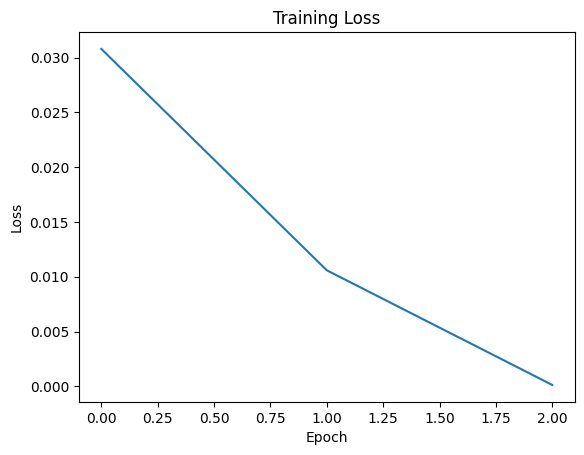

In [49]:
train_model(model, train_dataloader)

In [50]:
model.save_pretrained('/content/drive/MyDrive/SkillSwap/Saved Adapters/Intent_Router_Lora')

---

## Inference Cell

In [51]:
device = 'cuda'

In [52]:
MODEL_PATH = '/content/drive/MyDrive/SkillSwap/Saved Adapters/Intent_Router_Lora'

In [53]:
from peft import PeftModel

base_model = AutoModelForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels = 3)
model = PeftModel.from_pretrained(base_model, MODEL_PATH)
model.to(device)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


PeftModelForSequenceClassification(
  (base_model): LoraModel(
    (model): DistilBertForSequenceClassification(
      (distilbert): DistilBertModel(
        (embeddings): Embeddings(
          (word_embeddings): Embedding(30522, 768, padding_idx=0)
          (position_embeddings): Embedding(512, 768)
          (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (transformer): Transformer(
          (layer): ModuleList(
            (0-5): 6 x TransformerBlock(
              (attention): MultiHeadSelfAttention(
                (dropout): Dropout(p=0.1, inplace=False)
                (q_lin): lora.Linear(
                  (base_layer): Linear(in_features=768, out_features=768, bias=True)
                  (lora_dropout): ModuleDict(
                    (default): Dropout(p=0.1, inplace=False)
                  )
                  (lora_A): ModuleDict(
                    (default): Linear(in_features=768

In [55]:
label_names = tokenized_datasets['train'].features['labels'].names

text = 'Tell me about Kaustubh Bag.'

inputs = tokenizer(text, return_tensors = 'pt', truncation = True, padding = True)
inputs = {k: v.to(device) for k, v in inputs.items()}

model.eval()

with torch.no_grad():
    outputs = model(**inputs)
    predicted_id = torch.argmax(outputs.logits, dim = 1).item()

print("Predicted Label: ", label_names[predicted_id])

Predicted Label:  2
